#### EDA – Code Assignment - Part 03

✅ Q1. Import required libraries:

In [85]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


✅ Q2. Load the Google Play Store dataset into a DataFrame.

In [86]:
df = pd.read_csv('data/google_store.csv')


Q3. Display:

- first 5 rows
- dataset shape
- dataset info

In [87]:
df.head(5)


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


In [88]:
df.shape

(10841, 13)

In [89]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  object 
 1   Category        10841 non-null  object 
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  object 
 4   Size            10841 non-null  object 
 5   Installs        10841 non-null  object 
 6   Type            10840 non-null  object 
 7   Price           10841 non-null  object 
 8   Content Rating  10840 non-null  object 
 9   Genres          10841 non-null  object 
 10  Last Updated    10841 non-null  object 
 11  Current Ver     10833 non-null  object 
 12  Android Ver     10838 non-null  object 
dtypes: float64(1), object(12)
memory usage: 1.1+ MB


✅ Q4. Find total missing values column-wise.

In [90]:
df.isnull().sum()

App                  0
Category             0
Rating            1474
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       1
Genres               0
Last Updated         0
Current Ver          8
Android Ver          3
dtype: int64

✅ Q6. Convert the Reviews column into integer type.

In [91]:
df['Reviews'].unique()

array(['159', '967', '87510', ..., '603', '1195', '398307'],
      shape=(6002,), dtype=object)

In [92]:
df[~df['Reviews'].str.isnumeric()]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
10472,Life Made WI-Fi Touchscreen Photo Frame,1.9,19.0,3.0M,"1,000+",Free,0,Everyone,NaN,"February 11, 2018",1.0.19,4.0 and up,NaN


In [93]:
df = df.drop(df.index[10472])

In [94]:
# 
df['Reviews'] = df['Reviews'].astype('int64')

In [95]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10840 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10840 non-null  object 
 1   Category        10840 non-null  object 
 2   Rating          9366 non-null   float64
 3   Reviews         10840 non-null  int64  
 4   Size            10840 non-null  object 
 5   Installs        10840 non-null  object 
 6   Type            10839 non-null  object 
 7   Price           10840 non-null  object 
 8   Content Rating  10840 non-null  object 
 9   Genres          10840 non-null  object 
 10  Last Updated    10840 non-null  object 
 11  Current Ver     10832 non-null  object 
 12  Android Ver     10838 non-null  object 
dtypes: float64(1), int64(1), object(11)
memory usage: 1.2+ MB


Q7. Clean the Size column by:

- removing 'M' and 'K'
- replacing "Varies with device" with NaN
- converting to float

In [96]:
df['Size'].unique()

array(['19M', '14M', '8.7M', '25M', '2.8M', '5.6M', '29M', '33M', '3.1M',
       '28M', '12M', '20M', '21M', '37M', '2.7M', '5.5M', '17M', '39M',
       '31M', '4.2M', '7.0M', '23M', '6.0M', '6.1M', '4.6M', '9.2M',
       '5.2M', '11M', '24M', 'Varies with device', '9.4M', '15M', '10M',
       '1.2M', '26M', '8.0M', '7.9M', '56M', '57M', '35M', '54M', '201k',
       '3.6M', '5.7M', '8.6M', '2.4M', '27M', '2.5M', '16M', '3.4M',
       '8.9M', '3.9M', '2.9M', '38M', '32M', '5.4M', '18M', '1.1M',
       '2.2M', '4.5M', '9.8M', '52M', '9.0M', '6.7M', '30M', '2.6M',
       '7.1M', '3.7M', '22M', '7.4M', '6.4M', '3.2M', '8.2M', '9.9M',
       '4.9M', '9.5M', '5.0M', '5.9M', '13M', '73M', '6.8M', '3.5M',
       '4.0M', '2.3M', '7.2M', '2.1M', '42M', '7.3M', '9.1M', '55M',
       '23k', '6.5M', '1.5M', '7.5M', '51M', '41M', '48M', '8.5M', '46M',
       '8.3M', '4.3M', '4.7M', '3.3M', '40M', '7.8M', '8.8M', '6.6M',
       '5.1M', '61M', '66M', '79k', '8.4M', '118k', '44M', '695k', '1.6M',
     

In [97]:
df['Size'] = df['Size'].str.replace('M','000')
df['Size'] = df['Size'].str.replace('k','')
df['Size'] = df['Size'].replace('Varies with device',np.nan)
df['Size'] = df['Size'].astype(float)



✅ Q8. Clean the Installs column by removing '+' and ',' and converting to integer.

In [98]:
df['Installs'][:10]

0        10,000+
1       500,000+
2     5,000,000+
3    50,000,000+
4       100,000+
5        50,000+
6        50,000+
7     1,000,000+
8     1,000,000+
9        10,000+
Name: Installs, dtype: object

In [99]:
df['Installs'] = df['Installs'].str.replace(',','')
df['Installs'] = df['Installs'].str.replace('+','')

In [100]:
df['Installs'] = df['Installs'].astype('int64')
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10840 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10840 non-null  object 
 1   Category        10840 non-null  object 
 2   Rating          9366 non-null   float64
 3   Reviews         10840 non-null  int64  
 4   Size            9145 non-null   float64
 5   Installs        10840 non-null  int64  
 6   Type            10839 non-null  object 
 7   Price           10840 non-null  object 
 8   Content Rating  10840 non-null  object 
 9   Genres          10840 non-null  object 
 10  Last Updated    10840 non-null  object 
 11  Current Ver     10832 non-null  object 
 12  Android Ver     10838 non-null  object 
dtypes: float64(2), int64(2), object(9)
memory usage: 1.2+ MB


✅ Q9. Remove '$' sign from Price column and convert to float.

In [101]:
df['Price'].unique()[:10]

array(['0', '$4.99', '$3.99', '$6.99', '$1.49', '$2.99', '$7.99', '$5.99',
       '$3.49', '$1.99'], dtype=object)

In [102]:
df['Price'] = df['Price'].str.replace('$','')

Q10. Handle missing values using:

- median for numerical columns
- mode for categorical columns

In [113]:
df.isnull().sum()

App               0
Category          0
Rating            0
Reviews           0
Size              0
Installs          0
Type              0
Price             0
Content Rating    0
Genres            0
Last Updated      0
Current Ver       0
Android Ver       0
dtype: int64

In [ ]:
df['Rating'] = df['Rating'].fillna(df['Rating']).median()
df['Size'] = df['Size'].fillna(df['Size']).median()
df['Current Ver'].fillna(df['Current Ver'].mode()[0], inplace=True)
df['Android Ver'].fillna(df['Android Ver'].mode()[0], inplace=True)
df['Type'].fillna(df['Type'].mode()[0], inplace=True)

✅ Q11. Remove duplicate apps based on App column.

In [ ]:
df.drop_duplicates(subset='App',inplace=True,keep='first')
df[df.duplicated('App')]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver


✅ Q12. Convert Last Updated column into datetime format.

In [121]:
df['Last Updated'] = pd.to_datetime(df['Last Updated'])

Q13. Create new columns:

- Day
- Month
- Year

from Last Updated.

In [122]:
df['Last Update_Day'] = pd.to_datetime(df['Last Updated']).dt.day
df['Last Update_Month'] = pd.to_datetime(df['Last Updated']).dt.month
df['Last Update_Year'] = pd.to_datetime(df['Last Updated']).dt.year

In [125]:
df.drop('Last Updated',inplace=True,axis=1)

✅ Q14. Plot histograms for all numerical features.

In [ ]:
df.hist(figsize=(12,8))
plt.tight_layout()
plt.show()

✅ Q15. Plot boxplot to detect outliers in numerical columns.

<Axes: >

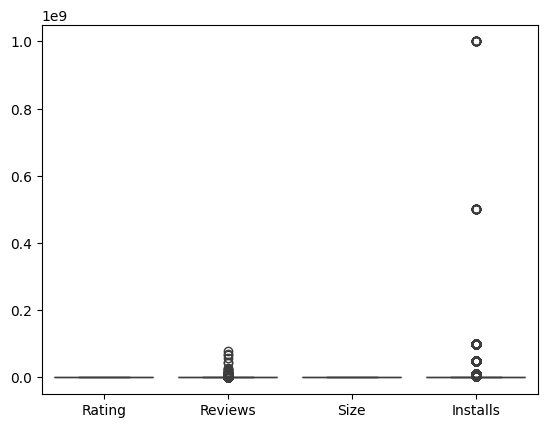

In [134]:
num_col = df.select_dtypes(include=['int64','float64'])
sns.boxplot(num_col)

✅ Q16. Plot countplot for Type column.

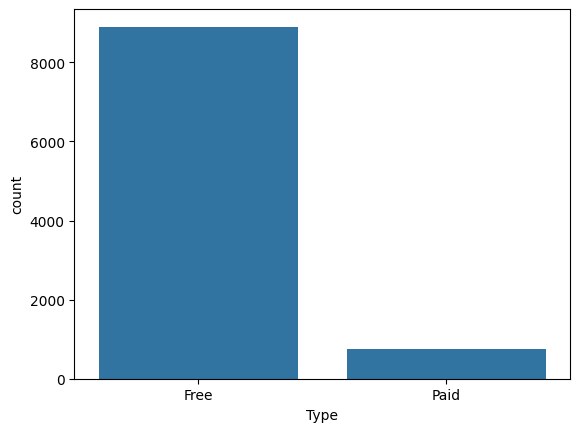

In [140]:
sns.countplot(x='Type',data=df)
plt.show()

✅ Q17. Plot countplot for Content Rating column.

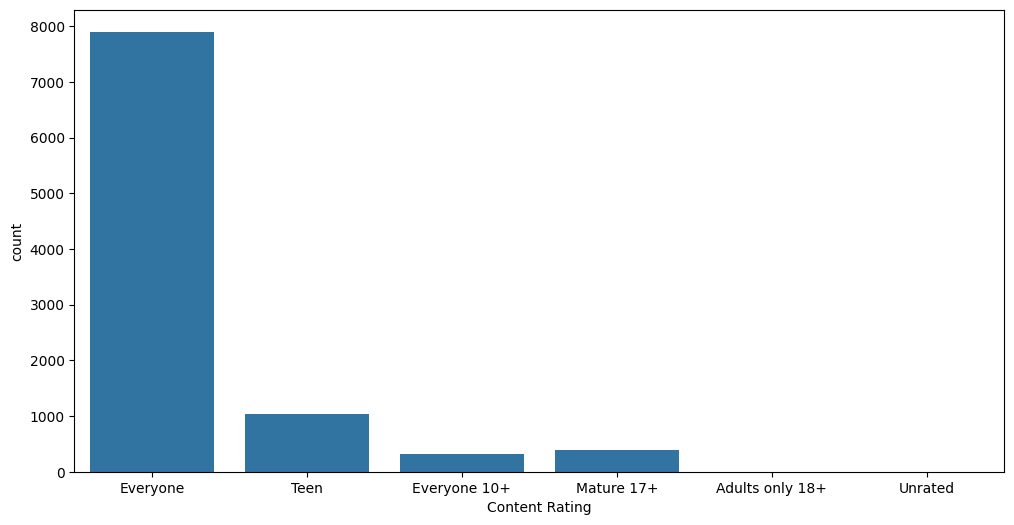

In [149]:
plt.figure(figsize=(12,6))
sns.countplot(x='Content Rating',data=df)
plt.show()

✅ Q18. Find top 10 most common app categories.

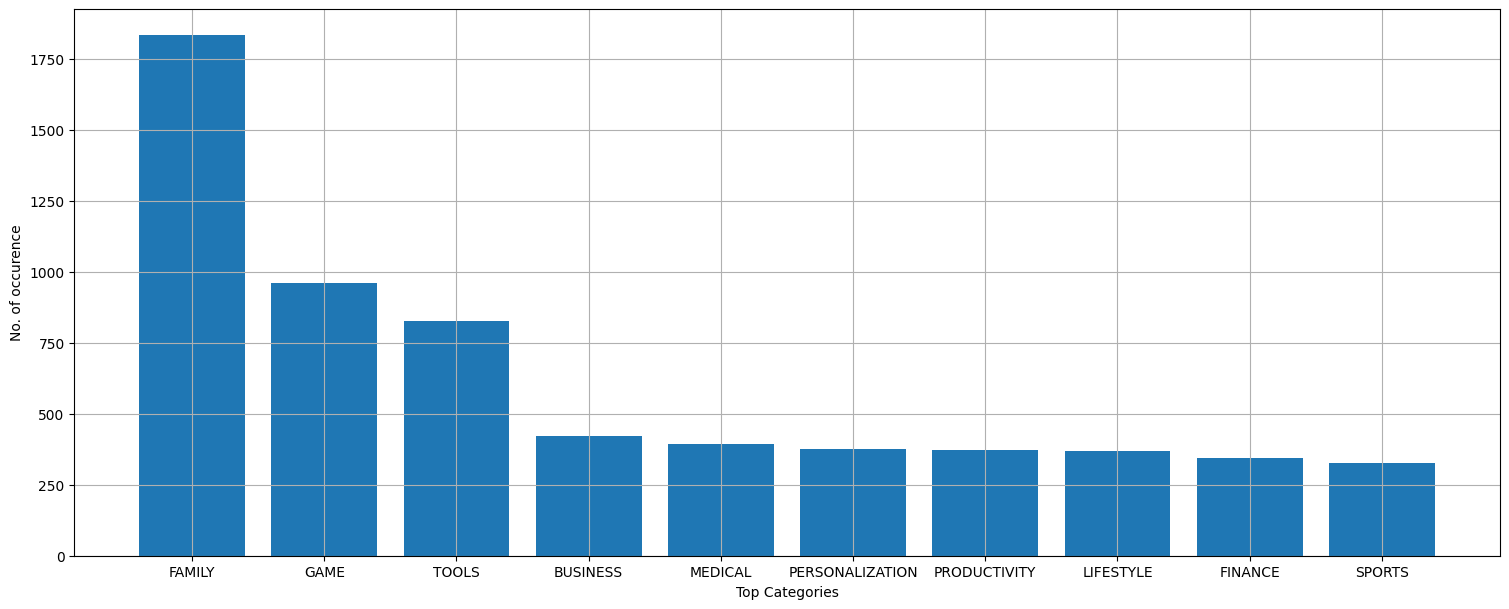

In [155]:
plt.figure(figsize=(15,6))
top_category = df['Category'].value_counts().nlargest(10)
plt.bar(top_category.index,top_category.values)
plt.tight_layout()
plt.xlabel('Top Categories')
plt.ylabel('No. of occurence')
plt.grid()
plt.show()

In [156]:
df.columns

Index(['App', 'Category', 'Rating', 'Reviews', 'Size', 'Installs', 'Type',
       'Price', 'Content Rating', 'Genres', 'Current Ver', 'Android Ver',
       'Last Update_Day', 'Last Update_Month', 'Last Update_Year'],
      dtype='object')

✅ Q20. Find category with highest total installs.

In [ ]:
category_install = df.groupby('Category')['Installs'].sum().sort_values(ascending=False)
category_install.plot(kind='bar',figsize=(12,6))
plt.show()

✅ Q21. Find the most installed app in each category.

In [ ]:
df.loc[df.groupby('Category')['Installs'].idxmax()][['Category','App','Installs']]


✅ Q22. Filter apps with perfect 5.0 rating.

In [167]:
five_star_apps = df[df['Rating'] == 5.0]
five_star_apps.head()


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Current Ver,Android Ver,Last Update_Day,Last Update_Month,Last Update_Year


✅ Q23. Compare free vs paid apps using boxplot of Price.

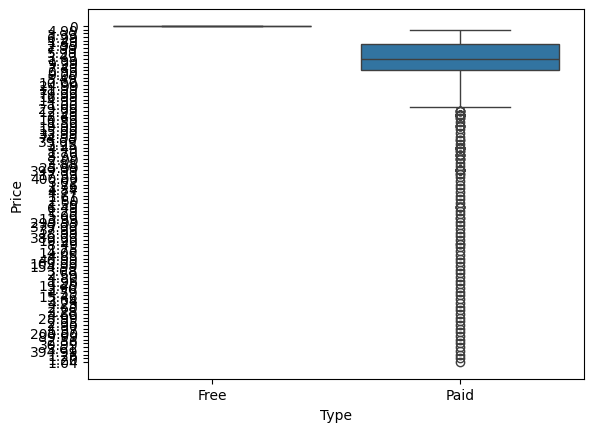

In [170]:
sns.boxplot(x='Type', y='Price', data=df)
plt.show()


✅ Q24. Plot scatter plot between Rating and Installs.

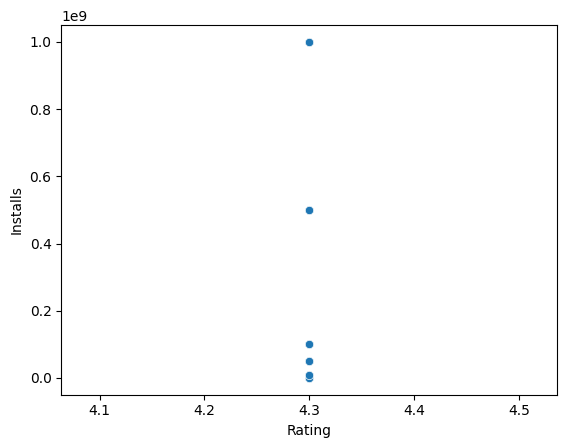

In [ ]:
sns.scatterplot(x='Rating', y='Installs', data=df)
plt.show()

✅ Q25. Save the cleaned dataset as a new CSV file.

In [172]:
df.to_csv('data/cleand_data/clean_google_store.csv')